## RQ3: Predicting flight delays

# Setup

### Setup and imports

In [1]:
from pathlib import Path
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterGrid

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import CLEAN_PARQUET, TABLES_DIR
from src.data_loading import load_flights

In [2]:
import warnings
# Unseen categories in a test month (e.g. a new route cluster) become missing values on purpose;
# the EBM handles them, so this display-only warning is switched off.
warnings.filterwarnings(
    "ignore",
    message=r"Missing values detected\. Our visualizations do not currently display missing values\.",
    category=UserWarning,
    module=r"interpret\.glassbox\._ebm\._ebm",
)

### Specifying columns/features

The features come from the flight data and from the outputs of RQ1 and RQ2. Each feature is listed with its source, so it is easy to check where it comes from.

In [3]:
FLIGHTS_SRC = "flights_2024_clean.parquet"

BASELINE_COLS = [
    ("route_past_delay_rate", "derived from training data separately for each split"),
]
# `month`: test months never appear in training, so for an unseen month the EBM uses the
# effect of the last training month. It works as a "recent delay level" feature. Checked on
# the validation months: removing it does not improve the model.
FLIGHT_COLS = [  # standard features from the original flight dataframe
    ("month", FLIGHTS_SRC),
    ("day_of_week", FLIGHTS_SRC),
    ("sched_hour", f"{FLIGHTS_SRC}: crs_dep_time // 100"),
    ("op_unique_carrier", FLIGHTS_SRC),
    ("distance", FLIGHTS_SRC),
]
RQ1_COLS = [
    ("route_cluster", "rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)"),
    ("cluster_past_delay_rate", "rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)"),
]
RQ2_COLS = [
    ("origin_community", "03_airports.csv: louvain (joined on origin)"),
    ("dest_community", "03_airports.csv: louvain (joined on dest)"),
    ("crosses_community", "derived: origin_community != dest_community"),
    ("origin_betweenness", "03_airports.csv: betweenness (joined on origin)"),
    ("dest_betweenness", "03_airports.csv: betweenness (joined on dest)"),
]
OTHER_COLS = [  # not features: route key for the baseline, and the target
    ("origin", FLIGHTS_SRC),
    ("dest", FLIGHTS_SRC),
    ("late_arrival", f"target, {FLIGHTS_SRC}: arr_delay >= 15"),
]

ROUTE_KEYS = ["origin", "dest", "op_unique_carrier"]

BASELINE_FEATURES = [column for column, _ in BASELINE_COLS]
FLIGHT_FEATURES = [column for column, _ in FLIGHT_COLS]
RQ1_FEATURES = [column for column, _ in RQ1_COLS]
RQ2_FEATURES = [column for column, _ in RQ2_COLS]


# Loading data

Standard flights and target

In [4]:
flights = load_flights(
    CLEAN_PARQUET,
    columns=["month", "day_of_week", "op_unique_carrier", "origin", "dest",
             "crs_dep_time", "distance", "status", "arr_delay"],
)
flights = flights.loc[flights["status"].eq("completed")].dropna(subset=["arr_delay"])
flights = flights.reset_index(drop=True)
flights["late_arrival"] = flights["arr_delay"].ge(15).astype(int)
flights["sched_hour"] = ((flights["crs_dep_time"] // 100) % 24).astype(int)
flights = flights.drop(columns=["status", "arr_delay", "crs_dep_time"])


RQ1: route clusters and historical delay rates (January–June)

In [5]:
route_clusters = pd.read_csv(TABLES_DIR / "rq1_route_clusters_jan_jun.csv")
cluster_rates = (
    pd.read_csv(TABLES_DIR / "rq1_cluster_delay_rates_jan_jun.csv")
    [["route_cluster", "historical_delay_rate"]]
    .rename(columns={"historical_delay_rate": "cluster_past_delay_rate"})
)

# Join route clusters and historical delay rates to the flights dataframe
flights = flights.merge(route_clusters, on=ROUTE_KEYS, how="left", validate="many_to_one")
flights = flights.merge(cluster_rates, on="route_cluster", how="left", validate="many_to_one")

RQ2: airport communities and betweenness 

In [6]:
airports = pd.read_csv(TABLES_DIR / "03_airports.csv")[["airport", "louvain", "betweenness"]]
for side in ["origin", "dest"]:
    features = airports.rename(columns={
        "airport": side,
        "louvain": f"{side}_community",
        "betweenness": f"{side}_betweenness",
    })
    flights = flights.merge(features, on=side, how="left", validate="many_to_one")

Build the final modelling table and add the `crosses_community` indicator.

In [7]:
group_cols = ["route_cluster", "origin_community", "dest_community"]
# Routes or airports without a cluster or community get the label "unknown".
for col in group_cols:
    flights[col] = flights[col].astype("Int64").astype("string").fillna("unknown")

# Indicator for flights between two different airport communities.
flights["crosses_community"] = flights["origin_community"].ne(flights["dest_community"]).astype(int)
rq3_df = flights[
    ["origin", "dest"] + FLIGHT_FEATURES + RQ1_FEATURES + RQ2_FEATURES + ["late_arrival"]
].copy()
del flights  # free memory: rq3_df holds everything we need

# Store the group labels as categories instead of text: same values, much less memory.
for col in group_cols:
    rq3_df[col] = rq3_df[col].astype("category")


Check the joins: the target rate and the share of flights without a cluster or community.

In [8]:
print(f"RQ3 modeling dataframe rows: {len(rq3_df):,}")
print(f"Target rate: {rq3_df['late_arrival'].mean():.3%}")
for col in group_cols:
    print(f"Unknown {col}: {rq3_df[col].eq('unknown').mean():.2%}")

feature_groups = [
    ("Baseline", BASELINE_COLS), ("Standard flight", FLIGHT_COLS),
    ("RQ1", RQ1_COLS), ("RQ2", RQ2_COLS), ("Other (not features)", OTHER_COLS),
]


listed = [col for col, _ in FLIGHT_COLS + RQ1_COLS + RQ2_COLS + OTHER_COLS]
assert sorted(listed) == sorted(rq3_df.columns)

RQ3 modeling dataframe rows: 6,965,246
Target rate: 20.817%
Unknown route_cluster: 1.83%
Unknown origin_community: 0.00%
Unknown dest_community: 0.00%


In [9]:
'''
Feature overview for RQ3 modeling dataframe
Note: route_past_delay_rate are supposed to be missing, we calculate them in each fold.
'''
for name, cols in feature_groups:
    print(f"\n{name}")
    for col, source in cols:
        is_col_in_df = col in rq3_df.columns
        status = "ok" if is_col_in_df else "computed inside each fold"
        print(f"    {col:<24} <- {source} ({status})")


Baseline
    route_past_delay_rate    <- derived from training data separately for each split (computed inside each fold)

Standard flight
    month                    <- flights_2024_clean.parquet (ok)
    day_of_week              <- flights_2024_clean.parquet (ok)
    sched_hour               <- flights_2024_clean.parquet: crs_dep_time // 100 (ok)
    op_unique_carrier        <- flights_2024_clean.parquet (ok)
    distance                 <- flights_2024_clean.parquet (ok)

RQ1
    route_cluster            <- rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier) (ok)
    cluster_past_delay_rate  <- rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster) (ok)

RQ2
    origin_community         <- 03_airports.csv: louvain (joined on origin) (ok)
    dest_community           <- 03_airports.csv: louvain (joined on dest) (ok)
    crosses_community        <- derived: origin_community != dest_community (ok)
    origin_betweenness       <- 03

### Feature groups

In [10]:
for name, features in [
    ("Baseline", BASELINE_FEATURES),
    ("standard_flight", FLIGHT_FEATURES),
    ("RQ1", RQ1_FEATURES),
    ("RQ2", RQ2_FEATURES),
]:
    print(f"{name}: {features}")

Baseline: ['route_past_delay_rate']
standard_flight: ['month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance']
RQ1: ['route_cluster', 'cluster_past_delay_rate']
RQ2: ['origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']


### Feature configurations

We need a better format to pick features, so we keep them in the FEATURE_CONFIGS dictionary, so we can pick and choose later

In [11]:
# Helper function to combine features without duplicates
def combine_features(*feature_lists):
    return list(dict.fromkeys(
        col
        for features in feature_lists
        for col in features
    ))


FEATURE_CONFIGS = {
    "Baseline": BASELINE_FEATURES,
    "standard_flight": FLIGHT_FEATURES,
    "RQ1": RQ1_FEATURES,
    "RQ2": RQ2_FEATURES,

    "Baseline + standard_flight": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES
    ),

    "Baseline + RQ1": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ1_FEATURES
    ),

    "Baseline + RQ2": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ2_FEATURES
    ),

    "Baseline + RQ1 + RQ2": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ1_FEATURES,
        RQ2_FEATURES
    )
}

In [12]:
# 4 Stand alone, 3 Baseline + other feature, 1 Full model
assert len(FEATURE_CONFIGS) == (4 + 3 + 1) 

# Show the number of features in each configuration
feature_config_table = pd.DataFrame([
    {"Feature Config": name, "Number of Features": len(features),
     "Features": ", ".join(features)}
    for name, features in FEATURE_CONFIGS.items()
])
display(feature_config_table)


,Feature Config,Number of Features,Features
0,Baseline,1,route_past_delay_rate
1,standard_flight,5,"month, day_of_week, sched_hour, op_unique_carr..."
2,RQ1,2,"route_cluster, cluster_past_delay_rate"
3,RQ2,5,"origin_community, dest_community, crosses_comm..."
4,Baseline + standard_flight,6,"route_past_delay_rate, month, day_of_week, sch..."
5,Baseline + RQ1,8,"route_past_delay_rate, month, day_of_week, sch..."
6,Baseline + RQ2,11,"route_past_delay_rate, month, day_of_week, sch..."
7,Baseline + RQ1 + RQ2,13,"route_past_delay_rate, month, day_of_week, sch..."


### Feature selection
Each configuration is fitted from scratch twice:

| Fold | Training months | Validation month |
| --- | --- | --- |
| July | 1–6 | 7 |
| August | 1–7 | 8 |


### Setup

In [13]:
VALIDATION_FOLDS = (
    {"fold": "July", "train_months": tuple(range(1, 7)), "validation_month": 7},
    {"fold": "August", "train_months": tuple(range(1, 8)), "validation_month": 8},
)
MODEL_TYPE = "EBM"
SELECTION_METRIC = "PR-AUC"  # threshold-free and suited to the ~20% late rate; recall at 0.5 is near 0
RANDOM_STATE = 42
# The EBM trains its outer bags in parallel, so more worker processes than bags add memory but no speed.
OUTER_BAGS = 4  # about 4x faster than the default 14 bags with the same ROC-AUC
N_JOBS = OUTER_BAGS
# None fits every training row. Set e.g. 200_000 for a quicker comparison;
# all configurations then receive the same sample within each fold.
SAMPLE_SIZE = 200_000
THRESHOLD = 0.5

### Functions
The historical delay rates (per route and per route cluster) are computed inside every fold from the training months only, so they never use the outcome of the flight they describe.

In [14]:
def historical_rate_table(train, keys, val_month, smoothing=20, initial_prior=0.5):
    """Smoothed late rate per key for every training month and for the validation month.

    A training row in month m only uses the training months before m (January has no
    history and gets initial_prior); the validation month uses all training months.
    The rates are computed on small monthly tables and joined to the rows afterwards,
    so no row ever sees its own outcome. Unknown route clusters are left out of the
    statistics and get the overall rate (prior) instead.
    """
    stats_rows = train
    if keys == ["route_cluster"]:
        stats_rows = train[train["route_cluster"].notna() & train["route_cluster"].ne("unknown")]
    monthly = (stats_rows.groupby(keys + ["month"], observed=True)["late_arrival"]
               .agg(["sum", "count"]).reset_index())
    month_totals = train.groupby("month", observed=True)["late_arrival"].agg(["sum", "count"])

    tables, priors = [], {}
    for month in sorted(train["month"].unique()) + [val_month]:
        history_months = month_totals.index[month_totals.index < month]
        totals = month_totals.loc[history_months].sum()
        prior = totals["sum"] / totals["count"] if totals["count"] > 0 else float(initial_prior)
        stats = (monthly[monthly["month"].isin(history_months)]
                 .groupby(keys, observed=True)[["sum", "count"]].sum().reset_index())
        stats["rate"] = (stats["sum"] + smoothing * prior) / (stats["count"] + smoothing)
        stats["month"] = month
        tables.append(stats[keys + ["month", "rate"]])
        priors[month] = prior
    return pd.concat(tables, ignore_index=True), priors

In [15]:
def add_rate(rows, rate_table, priors, keys, months):
    """Join the rate of each row's key and month; keys without history get that month's prior."""
    lookup = rows[keys].copy()
    lookup["month"] = months
    merged = lookup.merge(rate_table, on=keys + ["month"], how="left", validate="many_to_one", sort=False)
    return pd.Series(merged["rate"].fillna(merged["month"].map(priors)).to_numpy(), index=rows.index)

In [16]:
# Split one fold into training and validation rows, add the historical rates and fix the categorical types.
def prepare_fold(df, fold, sample_size=None, random_state=42):
    train = df[df["month"].isin(fold["train_months"])]  # read-only until sampled below
    val = df[df["month"].eq(fold["validation_month"])].copy()

    # Rate tables use the full training history; they are joined after sampling,
    # which gives the same values as computing them on every row first.
    rate_specs = [(ROUTE_KEYS, "route_past_delay_rate"), (["route_cluster"], "cluster_past_delay_rate")]
    rate_tables = {column: historical_rate_table(train, keys, fold["validation_month"])
                   for keys, column in rate_specs}

    n_available = len(train)

    # Apply the requested training sample; keep validation complete.
    if sample_size is not None and sample_size < n_available:
        train = train.sample(n=sample_size, random_state=random_state).copy()
    else:
        train = train.copy()

    for keys, column in rate_specs:
        table, priors = rate_tables[column]
        train[column] = add_rate(train, table, priors, keys, train["month"].to_numpy())
        val[column] = add_rate(val, table, priors, keys, fold["validation_month"])

    features = list(dict.fromkeys(
        col for cols in FEATURE_CONFIGS.values() for col in cols
    ))
    categorical = train[features].select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in categorical:
        train[col] = train[col].astype("category").cat.remove_unused_categories()
        categories = train[col].cat.categories

        # Explicitly replace unseen categories before casting.
        val[col] = (
            val[col]
            .where(val[col].isin(categories), other=pd.NA)
            .astype(train[col].dtype)
        )

    print(
        f"{fold['fold']}: training on {len(train):,}/{n_available:,} rows; "
        f"validating on {len(val):,} rows",
        flush=True,
    )
    return train, val, n_available

In [17]:
def evaluate_model(model, X, y, threshold=0.5):
    probs = model.predict_proba(X)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y, probs), # main metric, reported next to the base rate
        "PR-AUC": average_precision_score(y, probs), # main metric, reported next to the base rate
        "Log Loss": log_loss(y, probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, probs), # Don't think we will use this in report, but it is useful indicator when working
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0), # This turned out to be important for imbalanced datasets
        "F1": f1_score(y, preds, zero_division=0),
    }

### Training and validation of each feature configuration

In [18]:
def run_feature_selection(df, model, sample_size=SAMPLE_SIZE):
    rows = []
    for fold in VALIDATION_FOLDS:
        train, val, n_available = prepare_fold(df, fold, sample_size, RANDOM_STATE)
        period, month = f"1–{max(fold['train_months'])}", fold["validation_month"]

        for name, features in FEATURE_CONFIGS.items():
            print(f"EBM | {name} | train {period} → validate {month}")
            start = time.perf_counter()
            model.fit(train[features], train["late_arrival"])
            duration = time.perf_counter() - start

            for split, data in (("Train", train), ("Validation", val)):
                rows.append({
                    "Estimator": "EBM", "Feature Config": name,
                    "Number of Features": len(features), "Fold": fold["fold"],
                    "Train Period": period, "Validation Month": month, "Split": split,
                    "Available Train Samples": n_available, "Train Samples": len(train),
                    "Eval Samples": len(data), "Training Seconds": duration,
                    **evaluate_model(model, data[features], data["late_arrival"], THRESHOLD),
                })

    results = pd.DataFrame(rows)
    return results

In [19]:
# 4 outer bags trained in parallel keep the 16 fits fast.
model = ExplainableBoostingClassifier(
    random_state=RANDOM_STATE,
    interactions=0,
    n_jobs=N_JOBS,
    outer_bags=OUTER_BAGS,
    max_bins=256,       # Coarser numerical features.
    max_rounds=3000,    # Limit boosting rounds.
)

print(f"Logical CPU cores detected: {os.cpu_count()}")
print(f"Training with n_jobs={model.n_jobs} (one process per outer bag)", flush=True)

start = time.perf_counter()
results_df = run_feature_selection(rq3_df, model, sample_size=SAMPLE_SIZE)
elapsed = time.perf_counter() - start

print(f"Feature selection completed in {elapsed / 60:.1f} minutes ({elapsed:,.0f} seconds).")

validation_results = results_df[results_df["Split"] == "Validation"].copy()
display(validation_results.round(4))

Logical CPU cores detected: 20
Training with n_jobs=4 (one process per outer bag)
July: training on 200,000/3,403,472 rows; validating on 613,938 rows
EBM | Baseline | train 1–6 → validate 7
EBM | standard_flight | train 1–6 → validate 7
EBM | RQ1 | train 1–6 → validate 7
EBM | RQ2 | train 1–6 → validate 7
EBM | Baseline + standard_flight | train 1–6 → validate 7
EBM | Baseline + RQ1 | train 1–6 → validate 7
EBM | Baseline + RQ2 | train 1–6 → validate 7
EBM | Baseline + RQ1 + RQ2 | train 1–6 → validate 7
August: training on 200,000/4,017,410 rows; validating on 604,299 rows
EBM | Baseline | train 1–7 → validate 8
EBM | standard_flight | train 1–7 → validate 8
EBM | RQ1 | train 1–7 → validate 8
EBM | RQ2 | train 1–7 → validate 8
EBM | Baseline + standard_flight | train 1–7 → validate 8
EBM | Baseline + RQ1 | train 1–7 → validate 8
EBM | Baseline + RQ2 | train 1–7 → validate 8
EBM | Baseline + RQ1 + RQ2 | train 1–7 → validate 8
Feature selection completed in 3.5 minutes (208 seconds).


,Estimator,Feature Config,Number of Features,Fold,Train Period,Validation Month,Split,Available Train Samples,Train Samples,Eval Samples,Training Seconds,ROC-AUC,PR-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
1,EBM,Baseline,1,July,1–6,7,Validation,3403472,200000,613938,3.8276,0.5867,0.3605,0.6129,0.2101,0.7038,0.0000,0.0000,0.0000
3,EBM,standard_flight,5,July,1–6,7,Validation,3403472,200000,613938,7.8792,0.6685,0.4338,0.5790,0.1971,0.7038,0.4675,0.0002,0.0004
5,EBM,RQ1,2,July,1–6,7,Validation,3403472,200000,613938,2.5646,0.5239,0.3101,0.6218,0.2136,0.7038,0.0000,0.0000,0.0000
7,EBM,RQ2,5,July,1–6,7,Validation,3403472,200000,613938,8.3032,0.5472,0.3264,0.6217,0.2134,0.7038,0.0000,0.0000,0.0000
9,EBM,Baseline + standard_flight,6,July,1–6,7,Validation,3403472,200000,613938,7.9278,0.6731,0.4426,0.5748,0.1951,0.7061,0.5721,0.0315,0.0597
11,EBM,Baseline + RQ1,8,July,1–6,7,Validation,3403472,200000,613938,9.0022,0.6725,0.4414,0.5753,0.1953,0.7058,0.5654,0.0301,0.0572
13,EBM,Baseline + RQ2,11,July,1–6,7,Validation,3403472,200000,613938,16.4408,0.6723,0.4365,0.5757,0.1955,0.7044,0.5166,0.0344,0.0645
15,EBM,Baseline + RQ1 + RQ2,13,July,1–6,7,Validation,3403472,200000,613938,19.4338,0.6716,0.4351,0.5762,0.1958,0.7044,0.5164,0.0344,0.0645
17,EBM,Baseline,1,August,1–7,8,Validation,4017410,200000,604299,1.7276,0.6015,0.3028,0.5340,0.1758,0.7653,0.0000,0.0000,0.0000
19,EBM,standard_flight,5,August,1–7,8,Validation,4017410,200000,604299,7.7696,0.6719,0.3725,0.5231,0.1718,0.7651,0.4952,0.0624,0.1109


### Feature ranking
Rank feature configurations by mean validation PR-AUC across the two groups

All other metrics, fold variability, and the train–validation gap are reported for comparison but do not affect the ranking.


In [20]:

METRICS = [
    "PR-AUC", "ROC-AUC", "Log Loss", "Brier Score",
    "Accuracy", "Precision", "Recall", "F1"
]

In [21]:
# Average validation scores, and the selection metric for each month.
validation = validation_results.groupby("Feature Config", sort=False)
ranking = validation[METRICS].mean().add_prefix("Mean Validation ")
ranking = ranking.join(
    validation_results.pivot(
        index="Feature Config", columns="Validation Month", values=SELECTION_METRIC
    ).rename(columns={7: f"July {SELECTION_METRIC}", 8: f"August {SELECTION_METRIC}"})
)

# Compare stability, feature count, and training performance.
ranking[f"Validation {SELECTION_METRIC} SD"] = validation[SELECTION_METRIC].std()
ranking["Number of Features"] = pd.Series({k: len(v) for k, v in FEATURE_CONFIGS.items()})
ranking[f"Mean Train {SELECTION_METRIC}"] = (
    results_df.query("Split == 'Train'").groupby("Feature Config")[SELECTION_METRIC].mean()
)
ranking[f"Train–Validation {SELECTION_METRIC} Gap"] = (
    ranking[f"Mean Train {SELECTION_METRIC}"] - ranking[f"Mean Validation {SELECTION_METRIC}"]
)

# Rank by the selection metric, breaking ties by fewer features and then configuration name.
ranking = ranking.reset_index().sort_values(
    [f"Mean Validation {SELECTION_METRIC}", "Number of Features", "Feature Config"],
    ascending=[False, True, True], kind="stable", ignore_index=True,
)
ranking.insert(0, "Rank", range(1, len(ranking) + 1))

best = ranking.iloc[0]
best_config = best["Feature Config"]
best_features = FEATURE_CONFIGS[best_config].copy()

print(f"Selected features for EBM: {best_config}")
print(f"Mean validation {SELECTION_METRIC}: {best[f'Mean Validation {SELECTION_METRIC}']:.4f}")
print(f"Features: {best_features}")
display(ranking.round(4))

Selected features for EBM: Baseline + standard_flight
Mean validation PR-AUC: 0.4104
Features: ['route_past_delay_rate', 'month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance']


,Rank,Feature Config,Mean Validation PR-AUC,Mean Validation ROC-AUC,Mean Validation Log Loss,Mean Validation Brier Score,Mean Validation Accuracy,Mean Validation Precision,Mean Validation Recall,Mean Validation F1,July PR-AUC,August PR-AUC,Validation PR-AUC SD,Number of Features,Mean Train PR-AUC,Train–Validation PR-AUC Gap
0,1,Baseline + standard_flight,0.4104,0.6763,0.5487,0.1835,0.7341,0.5227,0.0787,0.1293,0.4426,0.3782,0.0455,6,0.3660,-0.0444
1,2,Baseline + RQ1,0.4090,0.6759,0.5479,0.1832,0.7339,0.5184,0.0740,0.1229,0.4414,0.3765,0.0459,8,0.3674,-0.0415
2,3,Baseline + RQ2,0.4054,0.6752,0.5496,0.1839,0.7323,0.4892,0.0834,0.1351,0.4365,0.3743,0.0439,11,0.3699,-0.0355
3,4,Baseline + RQ1 + RQ2,0.4042,0.6747,0.5490,0.1837,0.7325,0.4893,0.0799,0.1309,0.4351,0.3733,0.0437,13,0.3709,-0.0333
4,5,standard_flight,0.4032,0.6702,0.5510,0.1844,0.7344,0.4814,0.0313,0.0556,0.4338,0.3725,0.0433,5,0.3535,-0.0496
5,6,Baseline,0.3317,0.5941,0.5735,0.1929,0.7346,0.0000,0.0000,0.0000,0.3605,0.3028,0.0408,1,0.2778,-0.0539
6,7,RQ2,0.2943,0.5484,0.5822,0.1961,0.7346,0.0000,0.0000,0.0000,0.3264,0.2621,0.0455,5,0.2730,-0.0213
7,8,RQ1,0.2779,0.5209,0.5830,0.1965,0.7346,0.0000,0.0000,0.0000,0.3101,0.2458,0.0455,2,0.2607,-0.0172


In [22]:
# Save the fold scores and feature ranking.
prefix = "rq3_ebm_feature_selection"
results_df.to_csv(TABLES_DIR / f"{prefix}_fold_scores.csv", index=False)
ranking.to_csv(TABLES_DIR / f"{prefix}_ranking.csv", index=False)

# Record the selected features and how they were chosen.
selection = {
    "estimator": "EBM",
    "feature_config": best_config,
    "features": best_features,
    "selection_metric": SELECTION_METRIC,
    "aggregation": "unweighted mean over validation months 7 and 8",
    "mean_validation_score": float(ranking.loc[0, f"Mean Validation {SELECTION_METRIC}"]),
    "sample_size": SAMPLE_SIZE,
    "random_state": RANDOM_STATE,
    "folds": list(VALIDATION_FOLDS),
    "test_months": [10, 11, 12],  # month 9 is only used for training
}
(TABLES_DIR / f"{prefix}_selected.json").write_text(
    json.dumps(selection, indent=2), encoding="utf-8"
)
print(f"Saved {prefix} results and selected features to {TABLES_DIR}")

Saved rq3_ebm_feature_selection results and selected features to D:\ComputationalTools\results\tables


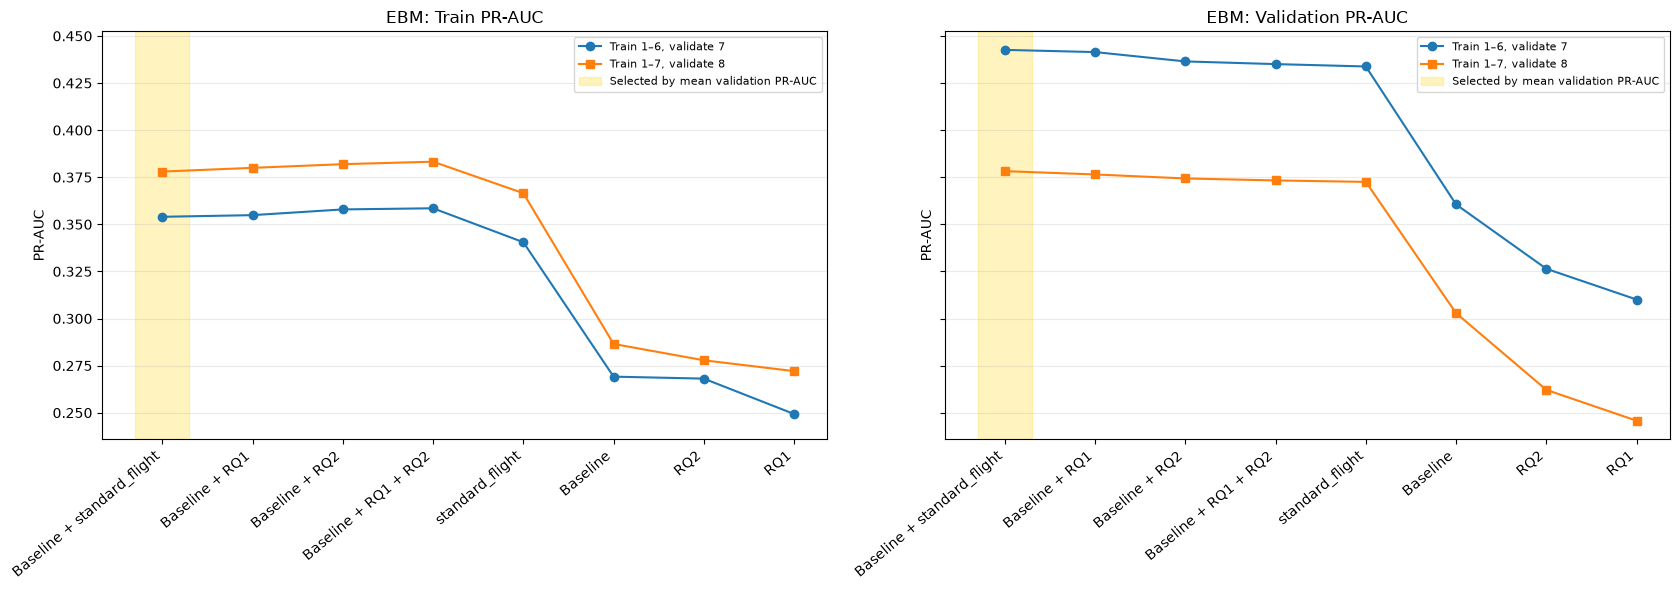

In [23]:
# Use the ranking order and highlight the selected configuration in both panels.
order = ranking["Feature Config"].tolist()
best_index = order.index(best_config)
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)

for ax, split in zip(axes, ["Train", "Validation"]):
    scores = results_df[results_df["Split"] == split].pivot(
        index="Feature Config", columns="Validation Month", values=SELECTION_METRIC
    ).loc[order]

    for month, marker in [(7, "o"), (8, "s")]:
        ax.plot(
            order, scores[month], marker=marker,
            label=f"Train 1–{month - 1}, validate {month}",
        )

    ax.axvspan(
        best_index - 0.3, best_index + 0.3, color="gold", alpha=0.25,
        label=f"Selected by mean validation {SELECTION_METRIC}",
    )
    ax.set(title=f"EBM: {split} {SELECTION_METRIC}", ylabel=SELECTION_METRIC)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

The configuration with the highest mean validation PR-AUC is selected (printed above). All configurations with the flight features are very close; the RQ3 question (do the RQ1 and RQ2 features help?) is answered on the test months at the end of the notebook.

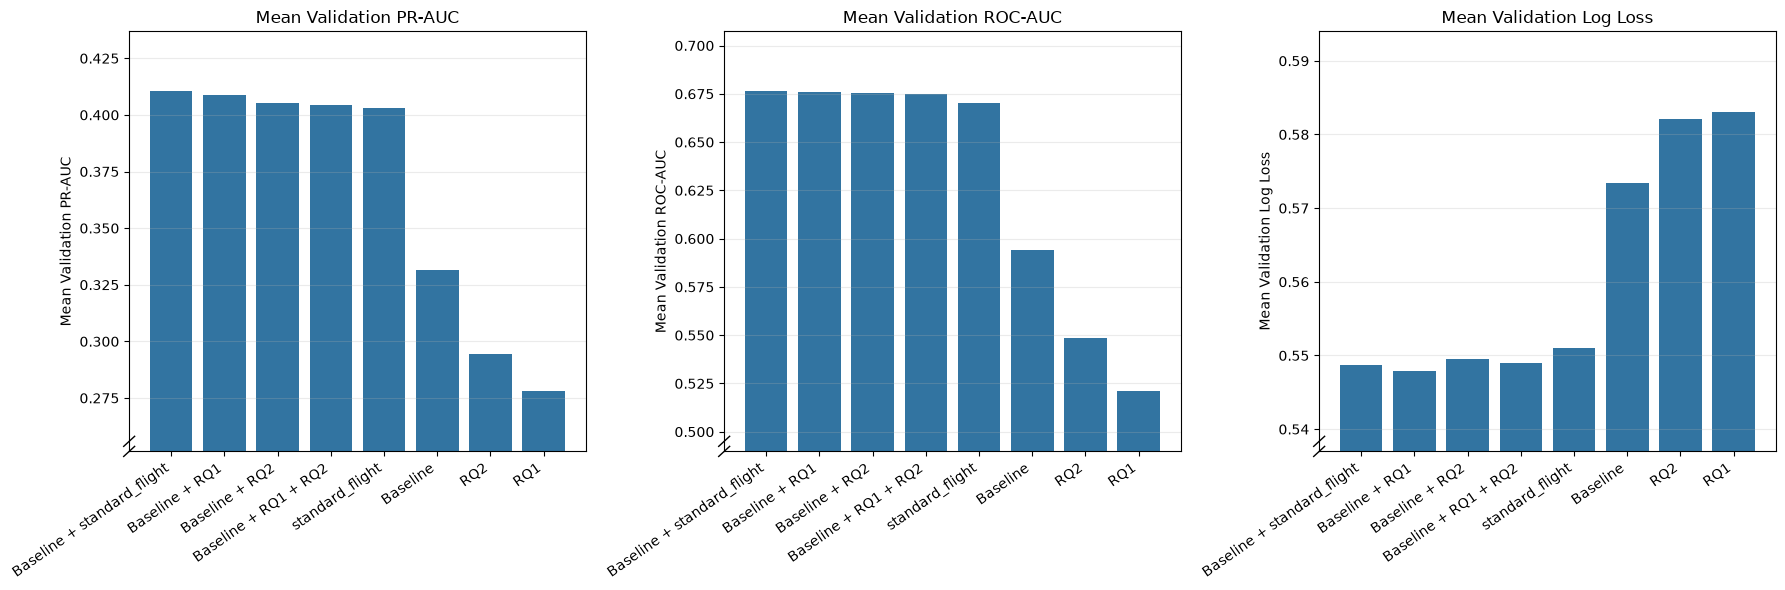

In [24]:
metrics = ["PR-AUC", "ROC-AUC", "Log Loss"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric in zip(axes, metrics):
    column = f"Mean Validation {metric}"
    sns.barplot(data=ranking, x="Feature Config", y=column,
                order=ranking["Feature Config"], ax=ax)

    # Zoom in to make differences between configurations easier to see.
    low, high = ranking[column].min(), ranking[column].max()
    padding = max((high - low) * 0.2, abs(low) * 0.02, 0.001)
    ax.set_ylim(low - padding, high + padding)

    # The slashes indicate that the y-axis does not start at zero.
    d = 0.012
    for offset in [0, 2 * d]:
        ax.plot(
            [-d, d], [-d + offset, d + offset],
            transform=ax.transAxes, color="black", clip_on=False, linewidth=1,
        )

    ax.set(title=column, xlabel="")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

The selected configuration is used for the hyperparameter tuning and as the main model on the test months.

# Hyperparameter tuning
We tune a small EBM grid on the selected features and choose the probability threshold for the confusion matrix. The threshold matters because only about 20% of the flights are late: at 0.5 the model predicts almost no late flights. The threshold is chosen by the mean F1 score over the validation months 7 and 8 only, and then kept fixed for the test months.

In [25]:
chosen_model = best_config  # selected above by mean validation PR-AUC

In [26]:
# Edit these lists to choose a grid; each combination is fitted once per fold.
EBM_PARAM_GRID = {
    "learning_rate": [0.015, 0.03],
    "max_leaves": [2, 3],
    "min_samples_leaf": [4],
    "interactions": [0, 3],
}
EBM_FIXED_PARAMS = {"random_state": RANDOM_STATE, "outer_bags": OUTER_BAGS, "n_jobs": N_JOBS}
PROBABILITY_THRESHOLDS = [0.1, 0.3, 0.5, 0.7]
TUNING_SAMPLE_SIZE = 50_000  # smaller sample: 8 configurations x 2 folds

print(f"Probability thresholds: {PROBABILITY_THRESHOLDS}")
print(f"Model fits: {len(ParameterGrid(EBM_PARAM_GRID))} configurations × {len(VALIDATION_FOLDS)} folds")

Probability thresholds: [0.1, 0.3, 0.5, 0.7]
Model fits: 8 configurations × 2 folds


In [27]:
def run_ebm_grid_search(df, feature_name, folds, param_grid, fixed_params,
                        thresholds, sample_size, random_state):
    features = FEATURE_CONFIGS[feature_name]
    combinations = list(ParameterGrid(param_grid))
    model_rows, threshold_rows = [], []

    for fold in folds:
        train, val, available = prepare_fold(df, fold, sample_size, random_state)
        X_train, y_train = train[features], train["late_arrival"]
        X_val, y_val = val[features], val["late_arrival"]

        for config_id, params in enumerate(combinations):
            print(f"{fold['fold']} | configuration {config_id + 1}/{len(combinations)} | {params}", flush=True)
            details = {
                "Configuration": config_id, "Fold": fold["fold"],
                "Validation Month": fold["validation_month"],
            }

            # Train once per configuration.
            model = ExplainableBoostingClassifier(**fixed_params, **params)
            start = time.perf_counter()
            model.fit(X_train, y_train)
            elapsed = time.perf_counter() - start
            probs = model.predict_proba(X_val)[:, 1]

            # Evaluate predicted probabilities.
            model_rows.append({
                **details, **params,
                "Available Train Samples": available, "Train Samples": len(train),
                "Validation Samples": len(val), "Training Seconds": elapsed,
                "ROC-AUC": roc_auc_score(y_val, probs),
                "PR-AUC": average_precision_score(y_val, probs),
                "Log Loss": log_loss(y_val, probs, labels=[0, 1]),
            })

            # Evaluate each classification threshold.
            for threshold in thresholds:
                preds = probs >= threshold
                threshold_rows.append({
                    **details, "Threshold": threshold,
                    "Recall": recall_score(y_val, preds, zero_division=0),
                    "Precision": precision_score(y_val, preds, zero_division=0),
                    "F1": f1_score(y_val, preds, zero_division=0),
                    "Positive Prediction Rate": preds.mean(),
                })

    return pd.DataFrame(model_rows), pd.DataFrame(threshold_rows)

### Running gridsearch

In [28]:
# Try each parameter combination and evaluate the probability thresholds.
tuning_folds, threshold_folds = run_ebm_grid_search(
    rq3_df, chosen_model, VALIDATION_FOLDS, EBM_PARAM_GRID, EBM_FIXED_PARAMS,
    PROBABILITY_THRESHOLDS, TUNING_SAMPLE_SIZE, RANDOM_STATE,
)

July: training on 50,000/3,403,472 rows; validating on 613,938 rows
July | configuration 1/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 2/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 3/8 | {'interactions': 0, 'learning_rate': 0.03, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 4/8 | {'interactions': 0, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 5/8 | {'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 6/8 | {'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 7/8 | {'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 8/8 | {'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
August: training on 50,000/4,017,410 rows; valid

### Display findings

In [29]:
# Rank configurations by their average validation PR-AUC.
combinations = list(ParameterGrid(EBM_PARAM_GRID))
parameters = pd.DataFrame(combinations).rename_axis("Configuration").reset_index()
metric_names = {
    "ROC-AUC": "Mean_ROC_AUC",
    "PR-AUC": "Mean_PR_AUC",
    "Log Loss": "Mean_log_loss",
    "Training Seconds": "Mean_training_seconds",
}
tuning_ranking = (
    tuning_folds.groupby("Configuration", as_index=False)[list(metric_names)].mean()
    .rename(columns=metric_names)
    .merge(parameters, on="Configuration", validate="one_to_one")
    .sort_values(["Mean_PR_AUC", "Configuration"], ascending=[False, True], ignore_index=True)
)

best_configuration = int(tuning_ranking.loc[0, "Configuration"])
best_ebm_params = {**EBM_FIXED_PARAMS, **combinations[best_configuration]}
interaction_comparison = tuning_ranking.groupby("interactions", as_index=False).first()

# For the selected model, choose the threshold with the highest mean F1.
# If two thresholds tie, prefer the higher threshold.
selected = threshold_folds[threshold_folds["Configuration"] == best_configuration]
threshold_metrics = ["Recall", "Precision", "F1", "Positive Prediction Rate"]
threshold_ranking = (
    selected.groupby("Threshold", as_index=False)[threshold_metrics].mean()
    .sort_values(["F1", "Threshold"], ascending=[False, False], ignore_index=True)
)
best_threshold = float(threshold_ranking.loc[0, "Threshold"])

print(f"Selected EBM parameters: {best_ebm_params}")
print(f"Selected threshold by mean F1: {best_threshold}")
print("Best model for each interaction setting:")
display(interaction_comparison.round(4))
display(tuning_ranking.round(4))
display(tuning_folds.sort_values(["Configuration", "Validation Month"]).round(4))
display(threshold_ranking.round(4))



Selected EBM parameters: {'random_state': 42, 'outer_bags': 4, 'n_jobs': 4, 'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
Selected threshold by mean F1: 0.3
Best model for each interaction setting:


,interactions,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,learning_rate,max_leaves,min_samples_leaf
0,0,3,0.6750,0.4076,0.5493,0.7918,0.03,3,4
1,3,7,0.6795,0.4106,0.5473,1.3524,0.03,3,4


,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,interactions,learning_rate,max_leaves,min_samples_leaf
0,7,0.6795,0.4106,0.5473,1.3524,3,0.030,3,4
1,4,0.6793,0.4105,0.5474,3.5042,3,0.015,2,4
2,5,0.6793,0.4105,0.5474,1.5688,3,0.015,3,4
3,6,0.6794,0.4104,0.5474,1.4501,3,0.030,2,4
4,3,0.6750,0.4076,0.5493,0.7918,0,0.030,3,4
5,2,0.6748,0.4073,0.5494,1.4317,0,0.030,2,4
6,1,0.6746,0.4073,0.5495,1.0327,0,0.015,3,4
7,0,0.6746,0.4072,0.5495,2.3366,0,0.015,2,4


,Configuration,Fold,Validation Month,interactions,learning_rate,max_leaves,min_samples_leaf,Available Train Samples,Train Samples,Validation Samples,Training Seconds,ROC-AUC,PR-AUC,Log Loss
0,0,July,7,0,0.015,2,4,3403472,50000,613938,1.5983,0.6730,0.4419,0.5763
8,0,August,8,0,0.015,2,4,4017410,50000,604299,3.0749,0.6762,0.3724,0.5226
1,1,July,7,0,0.015,3,4,3403472,50000,613938,0.8174,0.6730,0.4419,0.5767
9,1,August,8,0,0.015,3,4,4017410,50000,604299,1.2480,0.6763,0.3726,0.5223
2,2,July,7,0,0.030,2,4,3403472,50000,613938,1.0898,0.6732,0.4422,0.5762
10,2,August,8,0,0.030,2,4,4017410,50000,604299,1.7735,0.6764,0.3725,0.5225
3,3,July,7,0,0.030,3,4,3403472,50000,613938,0.5328,0.6736,0.4426,0.5764
11,3,August,8,0,0.030,3,4,4017410,50000,604299,1.0508,0.6764,0.3727,0.5223
4,4,July,7,3,0.015,2,4,3403472,50000,613938,2.5841,0.6803,0.4487,0.5736
12,4,August,8,3,0.015,2,4,4017410,50000,604299,4.4243,0.6782,0.3724,0.5211


,Threshold,Recall,Precision,F1,Positive Prediction Rate
0,0.3,0.5982,0.3912,0.4644,0.4095
1,0.1,0.9663,0.2847,0.4377,0.9053
2,0.5,0.1074,0.5081,0.1632,0.0558
3,0.7,0.0022,0.2274,0.0043,0.0011


### Ranking the best parameters

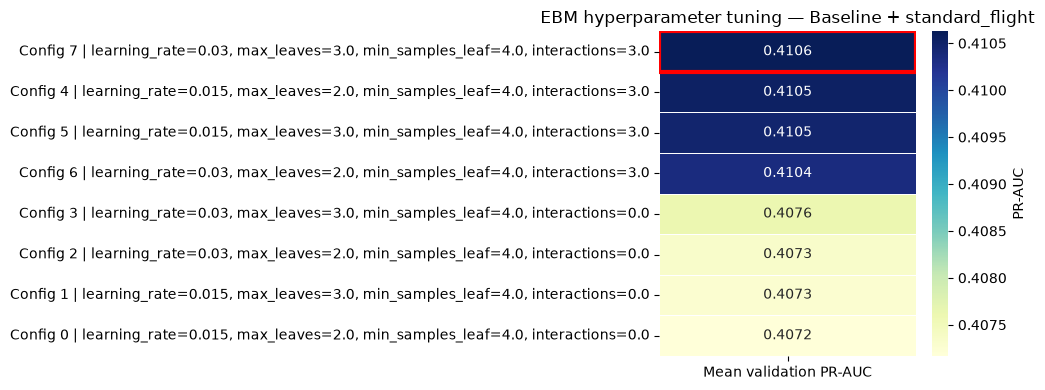

In [30]:
# Show the parameters next to each configuration so we can compare them.
heatmap_data = tuning_ranking.sort_values("Mean_PR_AUC", ascending=False).copy()
heatmap_data["Label"] = heatmap_data.apply(
    lambda row: f"Config {int(row['Configuration'])} | "
    + ", ".join(f"{p}={row[p]}" for p in EBM_PARAM_GRID),
    axis=1,
)
heatmap_data = (
    heatmap_data.set_index("Label")[["Mean_PR_AUC"]]
    .rename(columns={"Mean_PR_AUC": "Mean validation PR-AUC"})
)

fig, ax = plt.subplots(figsize=(10, max(4, len(heatmap_data) * 0.45)))
sns.heatmap(
    heatmap_data, annot=True, fmt=".4f", cmap="YlGnBu",
    linewidths=0.5, cbar_kws={"label": "PR-AUC"}, ax=ax,
)

# The best configuration is at the top; give it a red outline.
ax.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", linewidth=3))
ax.set(title=f"EBM hyperparameter tuning — {chosen_model}", xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [31]:
# Show all hyperparameter tuning results
display(tuning_ranking)

,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,interactions,learning_rate,max_leaves,min_samples_leaf
0,7,0.679477,0.410627,0.547345,1.352420,3,0.030,3,4
1,4,0.679272,0.410541,0.547372,3.504199,3,0.015,2,4
2,5,0.679261,0.410471,0.547439,1.568771,3,0.015,3,4
3,6,0.679392,0.410354,0.547367,1.450096,3,0.030,2,4
4,3,0.675000,0.407620,0.549314,0.791810,0,0.030,3,4
5,2,0.674771,0.407332,0.549355,1.431674,0,0.030,2,4
6,1,0.674649,0.407275,0.549497,1.032693,0,0.015,3,4
7,0,0.674573,0.407168,0.549484,2.336601,0,0.015,2,4


### Validation scores of the selected configuration

In [32]:
CONFIGURATION_ID = best_configuration
tuning_dir = TABLES_DIR

# Take this configuration from the grid above and use the same features and threshold.
params = {**EBM_FIXED_PARAMS, **list(ParameterGrid(EBM_PARAM_GRID))[CONFIGURATION_ID]}
features = FEATURE_CONFIGS[chosen_model]
threshold = best_threshold

rows = []
for fold in VALIDATION_FOLDS:
    train, val, _ = prepare_fold(rq3_df, fold, SAMPLE_SIZE, RANDOM_STATE)
    model = ExplainableBoostingClassifier(**params)
    model.fit(train[features], train["late_arrival"])

    rows.append({
        "Fold": fold["fold"], "Validation Month": fold["validation_month"],
        "Train Samples": len(train), "Validation Samples": len(val),
        "Threshold": threshold,
        **evaluate_model(model, val[features], val["late_arrival"], threshold),
    })

scores = pd.DataFrame(rows)
mean_scores = scores.iloc[:, 5:].mean().to_frame("Mean validation score")

print(f"Configuration {CONFIGURATION_ID}: {params}")
print(f"Probability threshold: {threshold}")
display(scores.round(4))
display(mean_scores.round(4))

scores.to_csv(tuning_dir / f"rq3_ebm_config_{CONFIGURATION_ID}_metrics.csv", index=False)
print(f"Saved per-fold metrics to {tuning_dir}")

July: training on 200,000/3,403,472 rows; validating on 613,938 rows
August: training on 200,000/4,017,410 rows; validating on 604,299 rows
Configuration 7: {'random_state': 42, 'outer_bags': 4, 'n_jobs': 4, 'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
Probability threshold: 0.3


,Fold,Validation Month,Train Samples,Validation Samples,Threshold,ROC-AUC,PR-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
0,July,7,200000,613938,0.3,0.6778,0.4451,0.5731,0.1939,0.6651,0.4456,0.5354,0.4864
1,August,8,200000,604299,0.3,0.6817,0.3770,0.5214,0.1723,0.6095,0.3357,0.6784,0.4492


,Mean validation score
ROC-AUC,0.6797
PR-AUC,0.4110
Log Loss,0.5472
Brier Score,0.1831
Accuracy,0.6373
Precision,0.3907
Recall,0.6069
F1,0.4678


Saved per-fold metrics to D:\ComputationalTools\results\tables


# Test on months 10–12
Each test month is predicted by a model trained on all earlier months (expanding window): to predict November the model only sees January–October. This is how the model would be used in practice, retrained every month as new data arrives. All choices (features, EBM parameters, threshold) were made on the validation months 7 and 8 only; month 9 is only used for training.

In every test month we train the same EBM on five feature sets with the same training sample, so the only difference between them is the features. This answers the RQ3 question: do the RQ1 route clusters and the RQ2 airport communities improve the prediction? The selected model is also evaluated at the chosen probability threshold (confusion matrix) and gives the term importances and shape plots.

We compare ROC-AUC and PR-AUC, which do not depend on a threshold. PR-AUC must be read next to the base rate (the share of late flights that month): a model that guesses has PR-AUC equal to the base rate.

In [33]:
TEST_PARAMS = best_ebm_params        # tuned on months 7-8 (includes outer_bags and n_jobs)
TEST_THRESHOLD = best_threshold
TEST_FEATURES = FEATURE_CONFIGS[chosen_model]
TEST_MONTHS = (10, 11, 12)
COMPARISON_CONFIGS = list(dict.fromkeys([
    "Baseline",
    "Baseline + standard_flight",
    "Baseline + RQ1",
    "Baseline + RQ2",
    "Baseline + RQ1 + RQ2",
    chosen_model,
]))

test_folds = [
    {"fold": str(month), "train_months": tuple(range(1, month)), "validation_month": month}
    for month in TEST_MONTHS
]
tables_dir = PROJECT_DIR / "results" / "tables"
figures_dir = PROJECT_DIR / "results" / "figures"
for directory in [tables_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)
print("Selected model:", chosen_model, "| parameters:", TEST_PARAMS, "| threshold:", TEST_THRESHOLD)

Selected model: Baseline + standard_flight | parameters: {'random_state': 42, 'outer_bags': 4, 'n_jobs': 4, 'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4} | threshold: 0.3


In [34]:
comparison_rows, test_rows, confusion_rows, importance_rows, test_models = [], [], [], [], {}
for fold in test_folds:
    month = fold["validation_month"]
    train, val, available = prepare_fold(rq3_df, fold, SAMPLE_SIZE, RANDOM_STATE)
    y = val["late_arrival"]

    for name in COMPARISON_CONFIGS:
        features = FEATURE_CONFIGS[name]
        model = ExplainableBoostingClassifier(**TEST_PARAMS)
        start = time.perf_counter()
        model.fit(train[features], train["late_arrival"])
        training_seconds = time.perf_counter() - start
        probs = model.predict_proba(val[features])[:, 1]
        comparison_rows.append({
            "Test Month": month, "Feature Config": name, "Number of Features": len(features),
            "Train Samples": len(train), "Test Samples": len(val), "Base Rate": y.mean(),
            "ROC-AUC": roc_auc_score(y, probs), "PR-AUC": average_precision_score(y, probs),
            "Training Seconds": training_seconds,
        })
        print(f"month {month} | {name}: ROC-AUC {comparison_rows[-1]['ROC-AUC']:.4f}", flush=True)
        if name != chosen_model:
            continue

        # Selected model: threshold metrics, confusion counts and term importances.
        test_models[month] = model
        preds = (probs >= TEST_THRESHOLD).astype(int)
        test_rows.append({
            "Test Month": month, "Training Months": f"1-{month - 1}",
            "Available Train Samples": available, "Train Samples": len(train),
            "Test Samples": len(val), "Threshold": TEST_THRESHOLD,
            "Training Seconds": training_seconds, "Base Rate": y.mean(),
            "PR-AUC": average_precision_score(y, probs),
            "ROC-AUC": roc_auc_score(y, probs),
            "Log Loss": log_loss(y, probs, labels=[0, 1]),
            "Brier Score": brier_score_loss(y, probs),
            "Accuracy": accuracy_score(y, preds),
            "Precision": precision_score(y, preds, zero_division=0),
            "Recall": recall_score(y, preds, zero_division=0),
            "F1": f1_score(y, preds, zero_division=0),
        })
        tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0, 1]).ravel()
        confusion_rows.append({"Test Month": month, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
        importance_rows.extend(
            {"Test Month": month, "Term": term, "Importance": importance}
            for term, importance in zip(model.term_names_, model.term_importances())
        )

10: training on 200,000/5,199,971 rows; validating on 608,513 rows
month 10 | Baseline: ROC-AUC 0.5840
month 10 | Baseline + standard_flight: ROC-AUC 0.6367
month 10 | Baseline + RQ1: ROC-AUC 0.6369
month 10 | Baseline + RQ2: ROC-AUC 0.6347
month 10 | Baseline + RQ1 + RQ2: ROC-AUC 0.6347
11: training on 200,000/5,808,484 rows; validating on 571,931 rows
month 11 | Baseline: ROC-AUC 0.5760
month 11 | Baseline + standard_flight: ROC-AUC 0.6147
month 11 | Baseline + RQ1: ROC-AUC 0.6146
month 11 | Baseline + RQ2: ROC-AUC 0.6145
month 11 | Baseline + RQ1 + RQ2: ROC-AUC 0.6144
12: training on 200,000/6,380,415 rows; validating on 584,831 rows
month 12 | Baseline: ROC-AUC 0.5699
month 12 | Baseline + standard_flight: ROC-AUC 0.6164
month 12 | Baseline + RQ1: ROC-AUC 0.6144
month 12 | Baseline + RQ2: ROC-AUC 0.6153
month 12 | Baseline + RQ1 + RQ2: ROC-AUC 0.6158


In [35]:
test_metrics = pd.DataFrame(test_rows)
metric_columns = [
    "Base Rate", "PR-AUC", "ROC-AUC", "Log Loss", "Brier Score",
    "Accuracy", "Precision", "Recall", "F1",
]

# Give each month the same weight, regardless of how many flights it has.
mean_row = {
    "Test Month": "Mean",
    "Training Months": "Equal-weight mean",
    **test_metrics[metric_columns].mean().to_dict(),
}
test_metrics = pd.concat([test_metrics, pd.DataFrame([mean_row])], ignore_index=True)

test_metrics.to_csv(tables_dir / "rq3_test_selected_model_metrics.csv", index=False)
display(test_metrics.round(4))

,Test Month,Training Months,Available Train Samples,Train Samples,Test Samples,Threshold,Training Seconds,Base Rate,PR-AUC,ROC-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
0,10,1-9,5199971.0,200000.0,608513.0,0.3,5.4230,0.1320,0.2023,0.6367,0.3790,0.1122,0.8482,0.2626,0.0829,0.1260
1,11,1-10,5808484.0,200000.0,571931.0,0.3,3.6011,0.1467,0.2064,0.6147,0.4087,0.1230,0.8507,0.3242,0.0163,0.0310
2,12,1-11,6380415.0,200000.0,584831.0,0.3,7.1738,0.2116,0.2886,0.6164,0.5199,0.1666,0.7829,0.3721,0.0384,0.0697
3,Mean,Equal-weight mean,NaN,NaN,NaN,NaN,NaN,0.1634,0.2324,0.6226,0.4359,0.1339,0.8273,0.3196,0.0459,0.0755


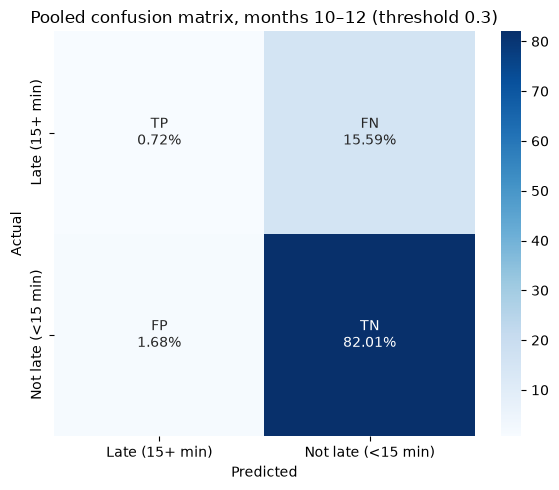

In [36]:
test_confusion = pd.DataFrame(confusion_rows)[
    ["Test Month", "TP", "FN", "FP", "TN"]
]
test_confusion.to_csv(
    tables_dir / "rq3_test_confusion.csv", index=False
)

pooled = test_confusion[["TP", "FN", "FP", "TN"]].sum()
total = pooled.sum()
if total == 0:
    raise ValueError("Cannot calculate percentages: no flights in the confusion matrix.")

percentages = pooled / total * 100
matrix = percentages.to_numpy().reshape(2, 2)
labels = [
    [f"{name}\n{percentages[name]:.2f}%" for name in row]
    for row in [("TP", "FN"), ("FP", "TN")]
]
classes = ["Late (15+ min)", "Not late (<15 min)"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    matrix, annot=labels, fmt="", cmap="Blues",
    xticklabels=classes, yticklabels=classes, ax=ax,
)
ax.set(
    title=f"Pooled confusion matrix, months 10–12 (threshold {TEST_THRESHOLD})",
    xlabel="Predicted", ylabel="Actual",
)

fig.tight_layout()
fig.savefig(figures_dir / "rq3_test_confusion.png", dpi=150)
plt.show()

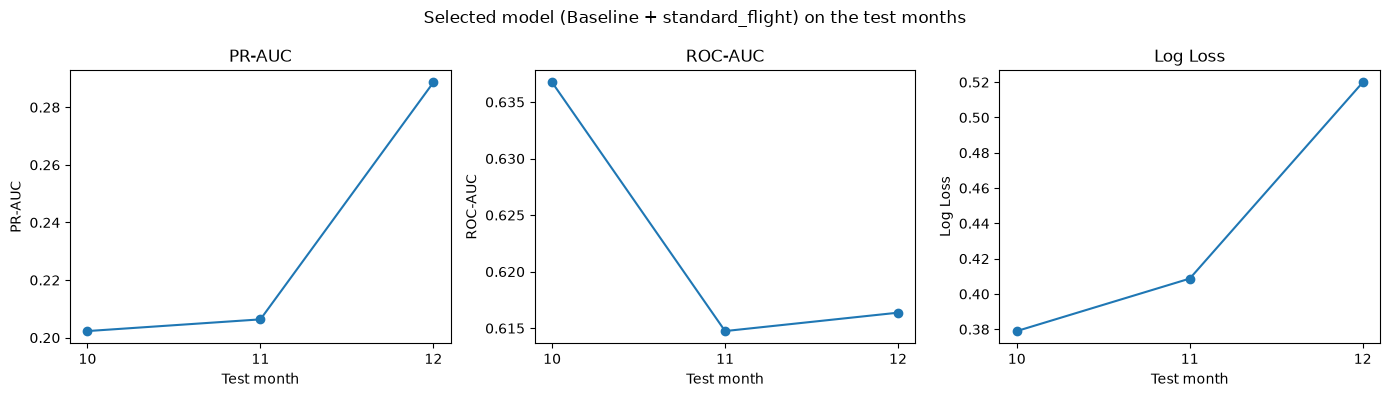

In [37]:
# Plot each month separately, leaving out the mean row.
monthly = test_metrics[test_metrics["Test Month"] != "Mean"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC", "Log Loss"]):
    ax.plot(TEST_MONTHS, monthly[metric], marker="o")
    ax.set(title=metric, xlabel="Test month", ylabel=metric, xticks=TEST_MONTHS)

fig.suptitle(f"Selected model ({chosen_model}) on the test months")
fig.tight_layout()
fig.savefig(figures_dir / "rq3_test_selected_model_metrics.png", dpi=150)
plt.show()

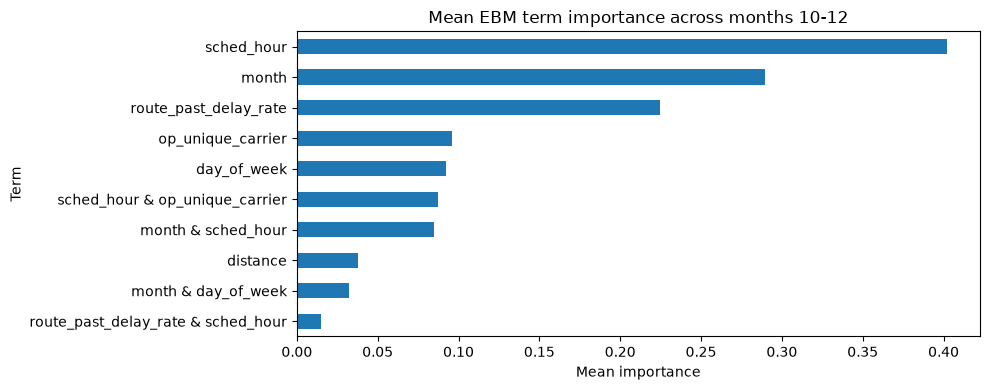

In [38]:
test_importance = pd.DataFrame(importance_rows)
test_importance.to_csv(tables_dir / "rq3_test_importance.csv", index=False)

# Count missing interactions as zero so every month contributes to the average.
mean_importance = (
    test_importance.pivot(index="Term", columns="Test Month", values="Importance")
    .reindex(columns=TEST_MONTHS, fill_value=0).fillna(0)
    .mean(axis=1).sort_values(ascending=False).rename("Mean Importance")
)
mean_importance.to_csv(tables_dir / "rq3_test_mean_importance.csv")

fig, ax = plt.subplots(figsize=(10, max(4, len(mean_importance) * 0.35)))
mean_importance.sort_values().plot.barh(ax=ax)
ax.set(
    title="Mean EBM term importance across months 10-12",
    xlabel="Mean importance", ylabel="Term",
)

fig.tight_layout()
fig.savefig(figures_dir / "rq3_test_importance.png", dpi=150)
plt.show()

In [39]:
feature_comparison = pd.DataFrame(comparison_rows)
feature_comparison.to_csv(tables_dir / "rq3_test_feature_comparison.csv", index=False)

# One row per feature set: the score in each month and the equal-weight mean.
comparison_summary = pd.concat({
    metric: feature_comparison.pivot(index="Feature Config", columns="Test Month", values=metric)
    for metric in ["ROC-AUC", "PR-AUC"]
}, axis=1).loc[COMPARISON_CONFIGS]
for metric in ["ROC-AUC", "PR-AUC"]:
    comparison_summary[(metric, "mean")] = comparison_summary[metric].mean(axis=1)
comparison_summary = comparison_summary.sort_index(axis=1, level=0, sort_remaining=False)
comparison_summary.to_csv(tables_dir / "rq3_test_feature_comparison_summary.csv")
display(comparison_summary.round(4))

# Gain of each set over the flight-only model (positive = better).
reference = comparison_summary.loc["Baseline + standard_flight"]
gain = (comparison_summary - reference).loc[["Baseline + RQ1", "Baseline + RQ2", "Baseline + RQ1 + RQ2"]]
print("Difference with Baseline + standard_flight (positive = better):")
display(gain.round(4))

PR-AUC                         ROC-AUC          \
Test Month                      10      11      12    mean      10      11   
Feature Config                                                               
Baseline                    0.1723  0.1871  0.2567  0.2054  0.5840  0.5760   
Baseline + standard_flight  0.2023  0.2064  0.2886  0.2324  0.6367  0.6147   
Baseline + RQ1              0.2023  0.2067  0.2867  0.2319  0.6369  0.6146   
Baseline + RQ2              0.2012  0.2066  0.2862  0.2313  0.6347  0.6145   
Baseline + RQ1 + RQ2        0.2010  0.2067  0.2868  0.2315  0.6347  0.6144   

                                            
Test Month                      12    mean  
Feature Config                              
Baseline                    0.5699  0.5766  
Baseline + standard_flight  0.6164  0.6226  
Baseline + RQ1              0.6144  0.6220  
Baseline + RQ2              0.6153  0.6215  
Baseline + RQ1 + RQ2        0.6158  0.6216

Difference with Baseline + standard_flight (positive = better):


PR-AUC                         ROC-AUC                  \
Test Month                10      11      12    mean      10      11      12   
Feature Config                                                                 
Baseline + RQ1        0.0000  0.0003 -0.0019 -0.0005  0.0002 -0.0002 -0.0019   
Baseline + RQ2       -0.0011  0.0002 -0.0024 -0.0011 -0.0021 -0.0003 -0.0011   
Baseline + RQ1 + RQ2 -0.0013  0.0003 -0.0019 -0.0009 -0.0021 -0.0004 -0.0006   

                              
Test Month              mean  
Feature Config                
Baseline + RQ1       -0.0006  
Baseline + RQ2       -0.0011  
Baseline + RQ1 + RQ2 -0.0010

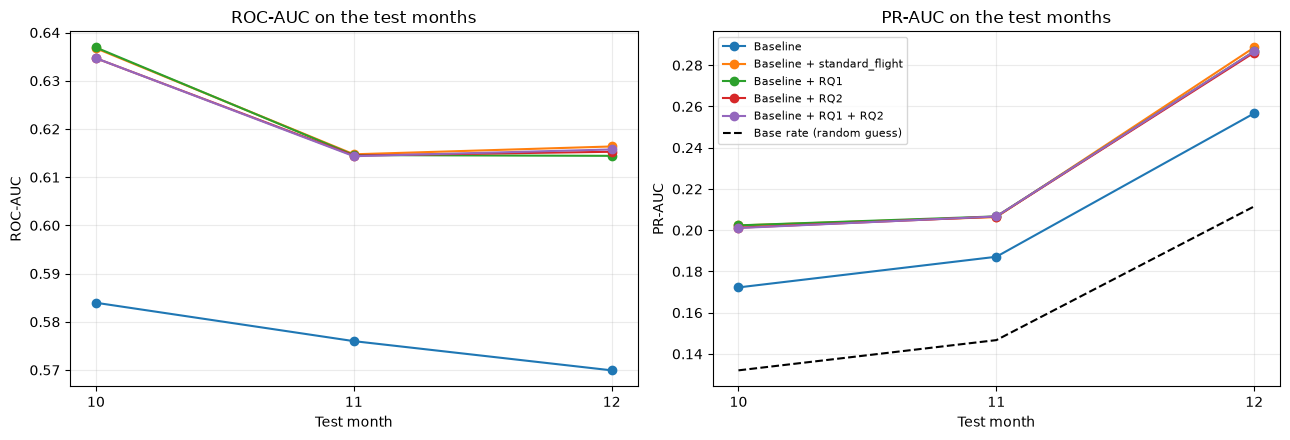

In [40]:
base_rates = feature_comparison.groupby("Test Month")["Base Rate"].first()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    for name in COMPARISON_CONFIGS:
        scores = feature_comparison[feature_comparison["Feature Config"] == name]
        ax.plot(scores["Test Month"], scores[metric], marker="o", label=name)
    if metric == "PR-AUC":
        ax.plot(base_rates.index, base_rates.values, color="black", linestyle="--", label="Base rate (random guess)")
    ax.set(title=f"{metric} on the test months", xlabel="Test month", ylabel=metric, xticks=TEST_MONTHS)
    ax.grid(alpha=0.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures_dir / "rq3_test_feature_comparison.png", dpi=150)
plt.show()

## What the EBM learned
An EBM is a sum of one curve per feature (plus a few pairwise interactions). Below are the curves of the selected model trained on months 1–11 (the model for December): the value is the contribution to the log-odds of a late arrival, so values above 0 raise the predicted risk and values below 0 lower it.

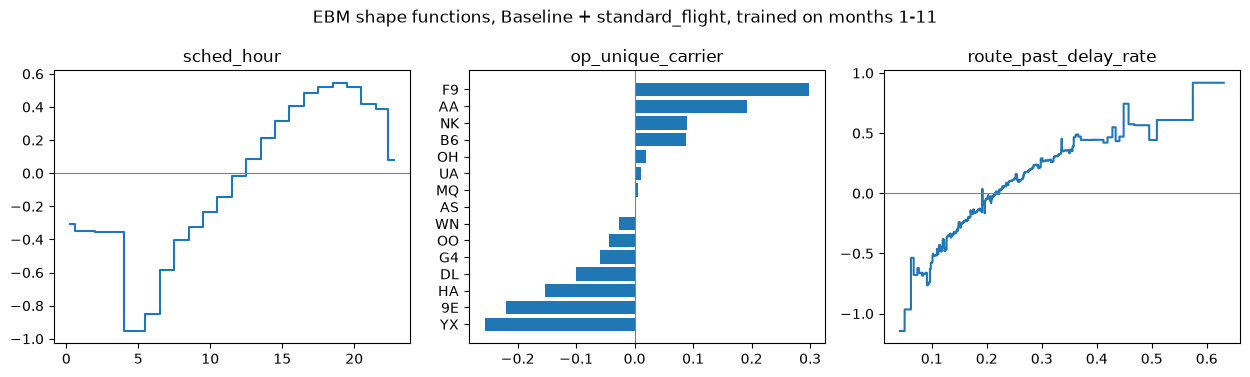

In [41]:
final_model = test_models[max(TEST_MONTHS)]
explanation = final_model.explain_global()
shape_terms = [term for term in ["sched_hour", "op_unique_carrier", "route_past_delay_rate", "route_cluster", "origin_community"]
               if term in final_model.term_names_]

fig, axes = plt.subplots(1, len(shape_terms), figsize=(4.2 * len(shape_terms), 3.8))
for ax, term in zip(axes, shape_terms):
    data = explanation.data(final_model.term_names_.index(term))
    scores = list(data["scores"])
    if final_model.feature_types_in_[list(final_model.feature_names_in_).index(term)] == "continuous":
        edges = list(data["names"])
        centres = [(edges[i] + edges[i + 1]) / 2 for i in range(len(scores))]
        ax.step(centres, scores, where="mid")
        ax.axhline(0, color="grey", linewidth=0.8)
    else:
        order = sorted(range(len(scores)), key=lambda i: scores[i])
        ax.barh([str(data["names"][i]) for i in order], [scores[i] for i in order])
        ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(term)
fig.suptitle(f"EBM shape functions, {chosen_model}, trained on months 1-{max(TEST_MONTHS) - 1}")
fig.tight_layout()
fig.savefig(figures_dir / "rq3_test_shape_functions.png", dpi=150)
plt.show()

**Takeaway (RQ3):**
- **Model choice (months 7–8):** the flight features (scheduled hour, month, weekday, airline, distance) plus the route delay rate give the best validation PR-AUC (0.410). Adding the RQ1 or RQ2 features gives slightly lower scores (0.404–0.409), so the selected model is *Baseline + standard_flight*. Tuning the EBM changes little (PR-AUC 0.407–0.411 over the grid).
- **Test months 10–12:** the selected model reaches a mean ROC-AUC of 0.623 and PR-AUC of 0.232, against 0.577 and 0.205 for the route baseline and a base rate of 0.13–0.21 (random guess). The model is clearly better than the baseline and than guessing, but the signal is weak: with only pre-flight information (no weather, no delay of the previous flight of the aircraft) most of a flight's delay cannot be predicted.
- **RQ3 answer:** adding the RQ1 route clusters, the RQ2 airport communities or both does **not** improve the prediction. In every test month the difference with the flight-only model is below 0.003 AUC, and on average slightly negative (−0.0005 to −0.0011). The clusters and communities do not carry information beyond the hour, airline, distance and route delay rate. This matches RQ1 and RQ2, where both groupings explain only a small part of the delay of a single flight.
- **What the EBM learned:** the scheduled hour is the most important feature (late-evening flights are the riskiest, early-morning the safest), followed by the month (for a new month it carries the most recent delay level), the route delay rate, the airline and the weekday. The shape plots above show these effects directly, which is why we chose an EBM.
- **Threshold:** the 0.3 threshold was chosen on July–August, when 24–30% of flights were late. In October–December only 13–21% are late, so the model predicts fewer flights as late and the recall drops to about 5% (precision 32%). The threshold-free scores (ROC-AUC, PR-AUC) are therefore the main results; the confusion matrix is only an illustration.